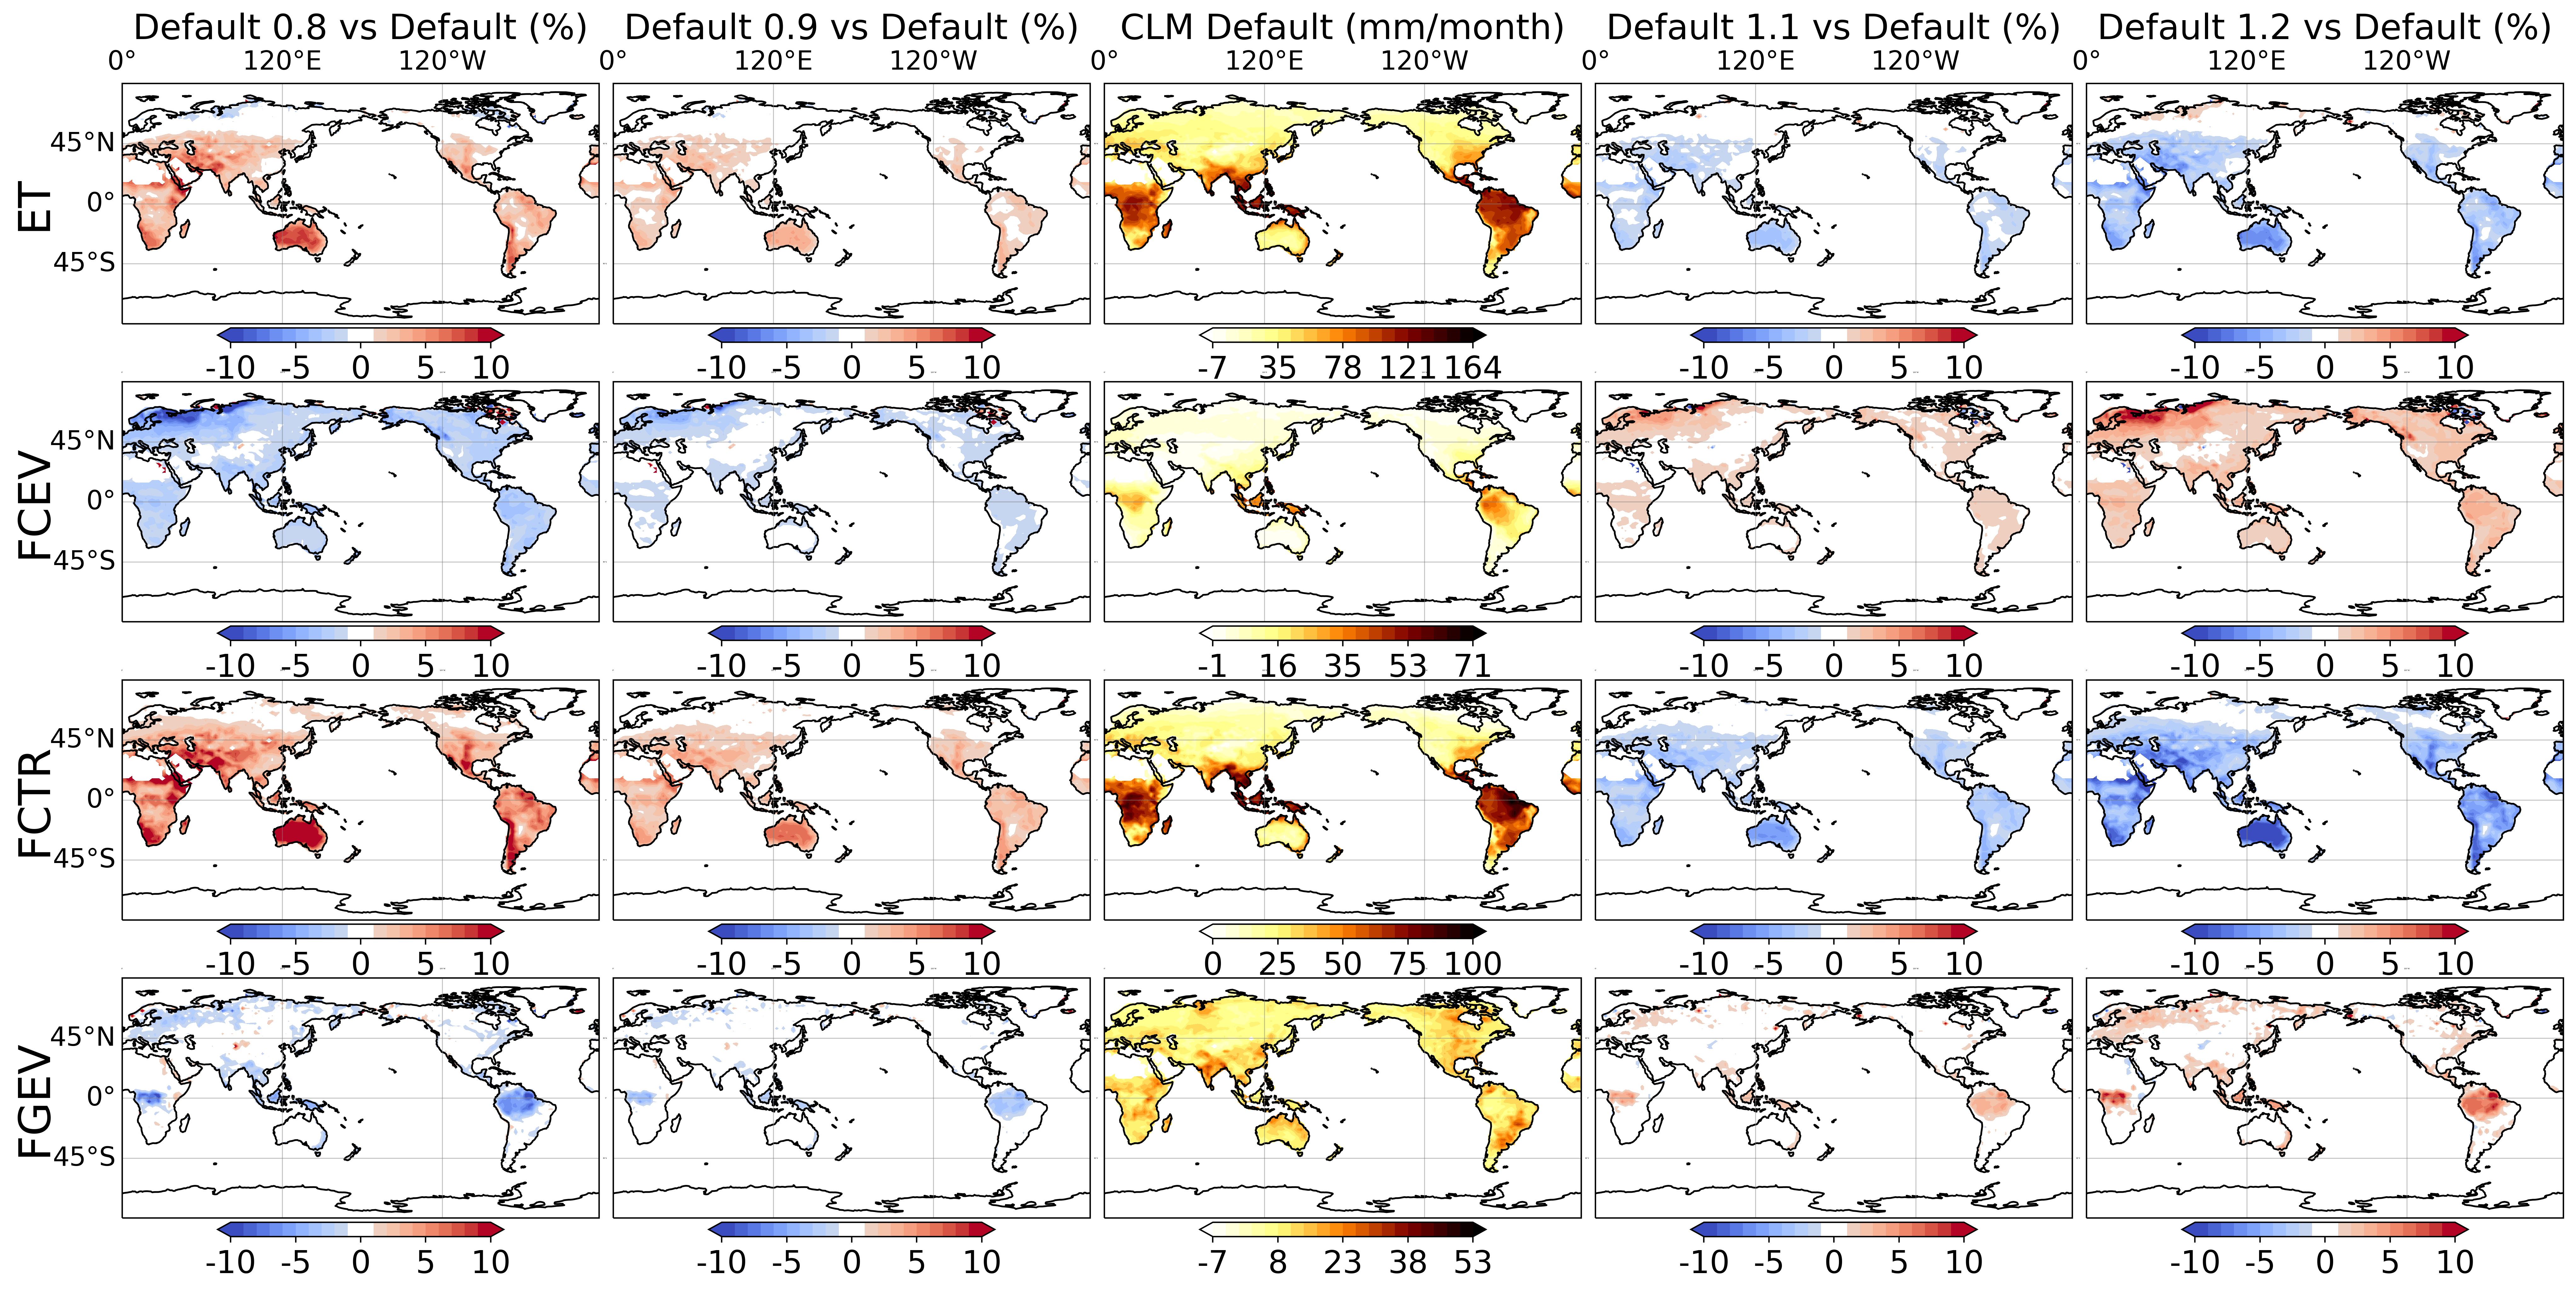

In [17]:
"""
Global maps of ET and its components (FCEV, FCTR, FGEV) for the CLM5
canopy-height sensitivity experiment.

Layout: 4 rows (ET, FCEV, FCTR, FGEV) x 5 columns
  col 0-1 : Default 0.8, 0.9  (% difference vs CLM Default)
  col 2   : CLM Default       (absolute, mm/month)
  col 3-4 : Default 1.1, 1.2  (% difference vs CLM Default)

Data source: G:/Hangkai/CTH_ET project/Final_data/*.nc
The flux variables there are stored as 1-D (pft,) vectors, so they are
gridded to (lat, lon) here via the pfts1d_ixy/jxy/wtgcell mapping.
"""

import os
import numpy as np
import netCDF4
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.colors import ListedColormap
from matplotlib import ticker

# --------------------------------------------------------------------------
# Configuration
# --------------------------------------------------------------------------
FILE_PATH = 'G:/Hangkai/CTH_ET project/Final_data/'

# display name -> Final_data filename (without .nc). CLM Default sits in the center.
scenario_mapping_EX = {
    'Default 0.8': 'Default 0.8',
    'Default 0.9': 'Default 0.9',
    'CLM Default': 'CLM Default',
    'Default 1.1': 'Default 1.1',
    'Default 1.2': 'Default 1.2',
}
scenarios = list(scenario_mapping_EX.keys())

variables = ['ET', 'FCEV', 'FCTR', 'FGEV']   # rows
flux_vars = ['FCEV', 'FCTR', 'FGEV']         # raw fields read from file (ET is derived)

# This is a forest canopy-height study, so maps show FOREST PFTs only.
# CLM tree PFTs: 1 NET Temp, 2 NET Bor, 3 NDT Bor, 4 BET Trop, 5 BET Temp,
#                6 BDT Trop, 7 BDT Temp, 8 BDT Bor. Set to None to use all vegetation.
FOREST_PFTS = set(range(1, 9))

WM2_TO_MM_MONTH = 1.0562   # mean monthly latent-heat flux (W/m^2) -> mm/month

# --------------------------------------------------------------------------
# Load grid + pft->gridcell mapping (identical across runs, read once)
# --------------------------------------------------------------------------
with netCDF4.Dataset(os.path.join(FILE_PATH, 'CLM Default.nc')) as ds:
    lat = np.asarray(ds.variables['lat'][:])
    lon = np.asarray(ds.variables['lon'][:])
    ix  = np.asarray(ds.variables['pfts1d_ixy'][:]).astype(int)        # lon index (1-based)
    jx  = np.asarray(ds.variables['pfts1d_jxy'][:]).astype(int)        # lat index (1-based)
    wt  = np.asarray(ds.variables['pfts1d_wtgcell'][:])                # pft weight within gridcell
    iv  = np.asarray(ds.variables['pfts1d_itype_veg'][:]).astype(int)  # pft type

nlat, nlon = len(lat), len(lon)
lon2d, lat2d = np.meshgrid(lon, lat)

# Restrict to forest patches (or keep all vegetation if FOREST_PFTS is None)
if FOREST_PFTS is None:
    sel = np.ones(iv.shape, dtype=bool)
else:
    sel = np.isin(iv, list(FOREST_PFTS))

ix_s, jx_s, wt_s = ix[sel], jx[sel], wt[sel]


def pft_to_grid(vec):
    """Aggregate a 1-D (pft,) flux vector to (lat, lon) as a forest-area-weighted mean.

    Only the selected (forest) patches contribute; gridcells with no forest -> NaN.
    """
    v = vec[sel]
    num = np.zeros((nlat, nlon))
    den = np.zeros((nlat, nlon))
    np.add.at(num, (jx_s - 1, ix_s - 1), v * wt_s)
    np.add.at(den, (jx_s - 1, ix_s - 1), wt_s)
    out = np.full((nlat, nlon), np.nan)   # cells with no forest stay NaN
    m = den > 0
    out[m] = num[m] / den[m]
    return out


# --------------------------------------------------------------------------
# Build gridded fields: annual_data_EX[variable][scenario] -> (lat, lon), W/m^2
# --------------------------------------------------------------------------
annual_data_EX = {v: {} for v in flux_vars}
for scen, fname in scenario_mapping_EX.items():
    with netCDF4.Dataset(os.path.join(FILE_PATH, fname + '.nc')) as ds:
        for v in flux_vars:
            annual_data_EX[v][scen] = pft_to_grid(np.asarray(ds.variables[v][:]))


def get_field(variable, scenario):
    """Return the (lat, lon) field for a variable/scenario, deriving ET as the sum."""
    if variable == 'ET':
        return (annual_data_EX['FCEV'][scenario]
                + annual_data_EX['FCTR'][scenario]
                + annual_data_EX['FGEV'][scenario])
    return annual_data_EX[variable][scenario]


# --------------------------------------------------------------------------
# Colormap with a white center for the % difference maps.
# Build it with exactly one color per contour bin so the white lands dead-center.
# --------------------------------------------------------------------------
pct_levels = np.linspace(-10, 10, num=21)          # 20 bins, symmetric about 0
n_bins = len(pct_levels) - 1                        # 20
colors = plt.get_cmap('coolwarm')(np.linspace(0, 1, n_bins))
mid = n_bins // 2                                   # 10
colors[mid - 1] = (1, 1, 1, 1)                      # bin covering [-1, 0]
colors[mid] = (1, 1, 1, 1)                          # bin covering [ 0, 1]
white_center_cmap = ListedColormap(colors)

# --------------------------------------------------------------------------
# Plot
# --------------------------------------------------------------------------
projection = ccrs.PlateCarree(central_longitude=180)

fig, axes = plt.subplots(len(variables), len(scenarios), figsize=(25, 18),
                         subplot_kw=dict(projection=projection), dpi=400)

for j, variable in enumerate(variables):
    for i, scenario in enumerate(scenarios):
        ax = axes[j, i]
        data_field = get_field(variable, scenario)

        if scenario == 'CLM Default':
            # Absolute field, converted to mm/month
            base = data_field.copy()
            base[base == 0] = np.nan
            plot_data = np.ma.masked_invalid(base * WM2_TO_MM_MONTH)
            title = 'CLM Default (mm/month)'
            colormap = plt.get_cmap('afmhot_r')
            vmin, vmax = np.nanmin(plot_data), np.nanmax(plot_data)
            levels = np.linspace(vmin, vmax, num=21)
            middle = 0.5 * (vmin + vmax)
            cbar_ticks = [vmin, 0.5 * (middle + vmin), middle,
                          0.5 * (middle + vmax), vmax]
        else:
            # Percent difference vs CLM Default
            base = get_field(variable, 'CLM Default').copy()
            base[base == 0] = np.nan
            plot_data = np.ma.masked_invalid((data_field - base) / base * 100)
            title = f'{scenario} vs Default (%)'
            colormap = white_center_cmap
            levels = pct_levels
            cbar_ticks = [-10, -5, 0, 5, 10]

        cs = ax.contourf(lon2d, lat2d, plot_data, levels=levels, cmap=colormap,
                         extend='both', transform=ccrs.PlateCarree())
        ax.coastlines()

        gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False,
                          linewidth=0.5, color='gray', alpha=0.5,
                          xlocs=[-120, 0, 120], ylocs=[-90, -45, 0, 45, 90])
        gl.bottom_labels = False
        gl.right_labels = False
        gl.xlabel_style = {'size': 15 if j == 0 else 0}   # longitude labels only on top row
        gl.ylabel_style = {'size': 15 if i == 0 else 0}   # latitude labels only on left column

        cbar = plt.colorbar(cs, ax=ax, orientation='horizontal', pad=0.005,
                            shrink=0.6, ticks=cbar_ticks)
        cbar.formatter = ticker.FormatStrFormatter('%.d')
        cbar.update_ticks()
        cbar.ax.tick_params(labelsize=18)

        if j == 0:
            ax.set_title(title, fontsize=20)

        if i == 0:
            ax.annotate(variable, xy=(-0.23, 0.5), xycoords='axes fraction',
                        fontsize=25, rotation=90, va='center')

plt.subplots_adjust(hspace=-0.65, wspace=0.03)
# plt.savefig('ET_sensitivity_maps.tif', dpi=300, bbox_inches='tight')
plt.show()